# Практическая работа № 1 — первичный анализ данных

**Студент:** Райымбердиев Исхак  
**Уровень:** B  
**Датасет:** Student Performance

Цель: загрузить данные, проверить их структуру и качество, рассчитать базовые статистики и построить первые визуализации.

In [1]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style='whitegrid')
pd.set_option('display.max_columns', 40)

candidates = [
    Path('data/student-mat.csv'),
    Path('../data/student-mat.csv'),
    Path('practice-1/data/student-mat.csv'),
]
DATA_PATH = next((path for path in candidates if path.exists()), None)
if DATA_PATH is None:
    raise FileNotFoundError('Не найден data/student-mat.csv')

df = pd.read_csv(DATA_PATH)
print(f'Файл: {DATA_PATH.resolve()}')
print(f'Размер датасета: {df.shape[0]} строк, {df.shape[1]} столбцов')
df.head()

Файл: /Users/zeus/ML/practice-1/data/student-mat.csv
Размер датасета: 395 строк, 33 столбцов


,school,sex,age,address,famsize,Parrent_status,Mother_edu,Father_edu,Mother_job,Father_job,reason_to_chose_school,guardian,traveltime,weekly_studytime,failures,extra_edu_supp,family_edu_supp,extra_paid_class,extra_curr_activities,nursery,Interested_in_higher_edu,internet_access,romantic_relationship,Family_quality_reln,freetime_after_school,goout_with_friends,workday_alcohol_consum,weekend_alcohol_consum,health_status,absences,G1,G2,G3
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10


## Структура и качество данных

In [2]:
print('Типы данных:')
display(df.dtypes.to_frame('dtype'))

quality = pd.DataFrame({
    'пропуски': df.isna().sum(),
    'доля пропусков, %': (df.isna().mean() * 100).round(2),
    'уникальных значений': df.nunique(),
})
display(quality)
print('Полных дубликатов:', df.duplicated().sum())

Типы данных:


,dtype
school,str
sex,str
age,int64
address,str
famsize,str
Parrent_status,str
Mother_edu,int64
Father_edu,int64
Mother_job,str
Father_job,str


,пропуски,"доля пропусков, %",уникальных значений
school,0,0.0,2
sex,0,0.0,2
age,0,0.0,8
address,0,0.0,2
famsize,0,0.0,2
Parrent_status,0,0.0,2
Mother_edu,0,0.0,5
Father_edu,0,0.0,5
Mother_job,0,0.0,5
Father_job,0,0.0,5


Полных дубликатов: 0


In [3]:
numeric_columns = df.select_dtypes(include=np.number).columns.tolist()
categorical_columns = df.select_dtypes(exclude=np.number).columns.tolist()
print('Числовые признаки:', numeric_columns)
print('Категориальные признаки:', categorical_columns)
display(df.describe().T)

Числовые признаки: ['age', 'Mother_edu', 'Father_edu', 'traveltime', 'weekly_studytime', 'failures', 'Family_quality_reln', 'freetime_after_school', 'goout_with_friends', 'workday_alcohol_consum', 'weekend_alcohol_consum', 'health_status', 'absences', 'G1', 'G2', 'G3']
Категориальные признаки: ['school', 'sex', 'address', 'famsize', 'Parrent_status', 'Mother_job', 'Father_job', 'reason_to_chose_school', 'guardian', 'extra_edu_supp', 'family_edu_supp', 'extra_paid_class', 'extra_curr_activities', 'nursery', 'Interested_in_higher_edu', 'internet_access', 'romantic_relationship']


,count,mean,std,min,25%,50%,75%,max
age,395.0,16.696203,1.276043,15.0,16.0,17.0,18.0,22.0
Mother_edu,395.0,2.749367,1.094735,0.0,2.0,3.0,4.0,4.0
Father_edu,395.0,2.521519,1.088201,0.0,2.0,2.0,3.0,4.0
traveltime,395.0,1.448101,0.697505,1.0,1.0,1.0,2.0,4.0
weekly_studytime,395.0,2.035443,0.839240,1.0,1.0,2.0,2.0,4.0
failures,395.0,0.334177,0.743651,0.0,0.0,0.0,0.0,3.0
Family_quality_reln,395.0,3.944304,0.896659,1.0,4.0,4.0,5.0,5.0
freetime_after_school,395.0,3.235443,0.998862,1.0,3.0,3.0,4.0,5.0
goout_with_friends,395.0,3.108861,1.113278,1.0,2.0,3.0,4.0,5.0
workday_alcohol_consum,395.0,1.481013,0.890741,1.0,1.0,1.0,2.0,5.0


## Визуализации

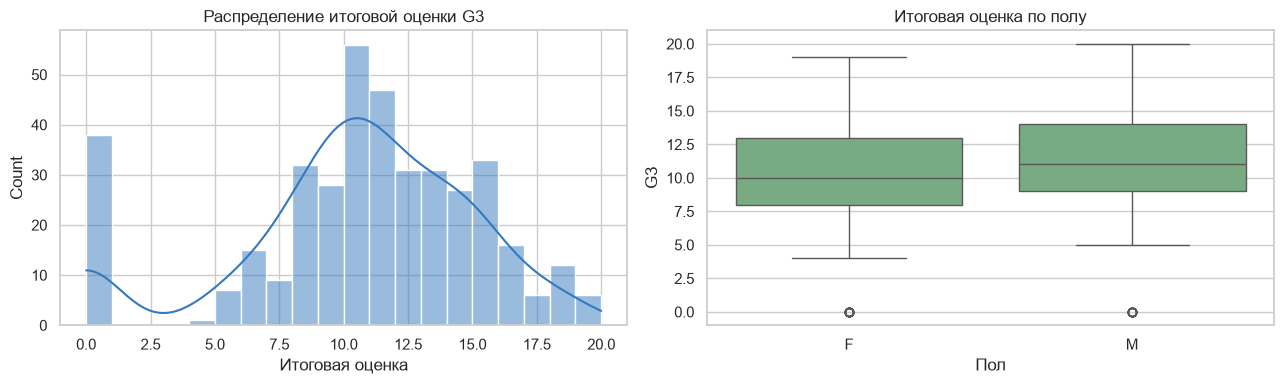

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))
sns.histplot(data=df, x='G3', bins=20, kde=True, ax=axes[0], color='#3478bf')
axes[0].set_title('Распределение итоговой оценки G3')
axes[0].set_xlabel('Итоговая оценка')

sns.boxplot(data=df, x='sex', y='G3', ax=axes[1], color='#71b37c')
axes[1].set_title('Итоговая оценка по полу')
axes[1].set_xlabel('Пол')
axes[1].set_ylabel('G3')
plt.tight_layout()
plt.show()

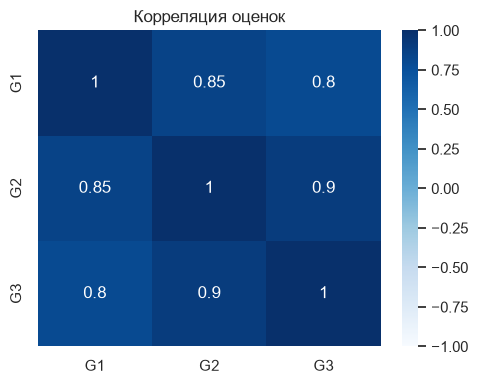

In [5]:
grade_corr = df[['G1', 'G2', 'G3']].corr()
plt.figure(figsize=(5, 4))
sns.heatmap(grade_corr, annot=True, cmap='Blues', vmin=-1, vmax=1)
plt.title('Корреляция оценок')
plt.tight_layout()
plt.show()

## Итоговые наблюдения

In [6]:
print(f"1. В таблице {len(df)} учеников и {df.shape[1]} признака; пропусков — {int(df.isna().sum().sum())}.")
print(f"2. Средняя итоговая оценка G3 равна {df['G3'].mean():.2f} из 20, медиана — {df['G3'].median():.0f}.")
print(f"3. Сильнее всего с G3 связана оценка G2: корреляция {df['G2'].corr(df['G3']):.3f}.")
print('4. Категориальные признаки перед машинным обучением потребуется закодировать.')

1. В таблице 395 учеников и 33 признака; пропусков — 0.
2. Средняя итоговая оценка G3 равна 10.42 из 20, медиана — 11.
3. Сильнее всего с G3 связана оценка G2: корреляция 0.905.
4. Категориальные признаки перед машинным обучением потребуется закодировать.
